# Series de tiempo 0 — Introducción y obtención de datos
**Versión comentada y ampliada del cuaderno original.**

## Objetivos
- Reconocer una serie temporal y su índice de fechas.
- Descargar y visualizar precios financieros con `yfinance`.
- Transformar datos históricos de COVID-19 desde formato ancho a una serie diaria.
- Consultar la TRM desde la API pública de datos.gov.co.

Este cuaderno es **exploratorio**: todavía no ajusta modelos de pronóstico. Los ejemplos dependen de fuentes externas, cuya disponibilidad puede cambiar.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

## 1. ¿Qué es una serie de tiempo?
Una serie temporal es una sucesión de observaciones \(X_t\) asociadas a instantes o períodos ordenados. Importan tanto los valores como **cuándo** se midieron.

Conviene distinguir **frecuencia** (diaria, mensual, etc.), **observaciones faltantes**, **intervalos irregulares**, **valor observado** y **valor imputado**. Una cotización ausente durante un cierre bursátil no equivale a un precio igual a cero.

`DatetimeIndex` permite conservar el calendario y seleccionar intervalos de fechas.

In [2]:
import yfinance as yf
def obtener_cierre(simbolo, inicio, fin):
    s = yf.Ticker(simbolo).history(start=inicio, end=fin)["Close"].copy()
    if s.empty:
        print(f"Sin cotizaciones: {simbolo}")
        return pd.Series(dtype=float, name=simbolo)
    s.index = pd.to_datetime(s.index).tz_localize(None).normalize()
    s = s.sort_index()
    s.name = simbolo
    return s

## 2. Cotizaciones: Bitcoin, Ecopetrol y Microsoft
Reproducimos los tres activos del cuaderno original: `BTC-USD`, `EC` y `MSFT`. Bitcoin suele cotizar todos los días; las acciones siguen calendarios bursátiles. Por ello no esperamos que sus índices tengan las mismas fechas.

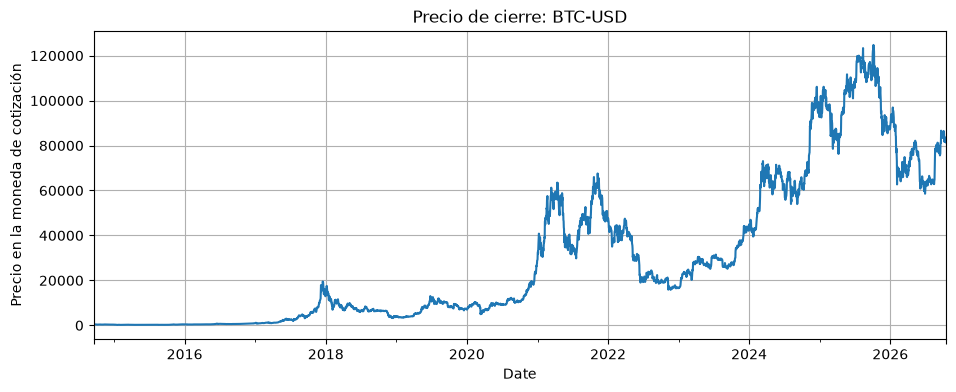

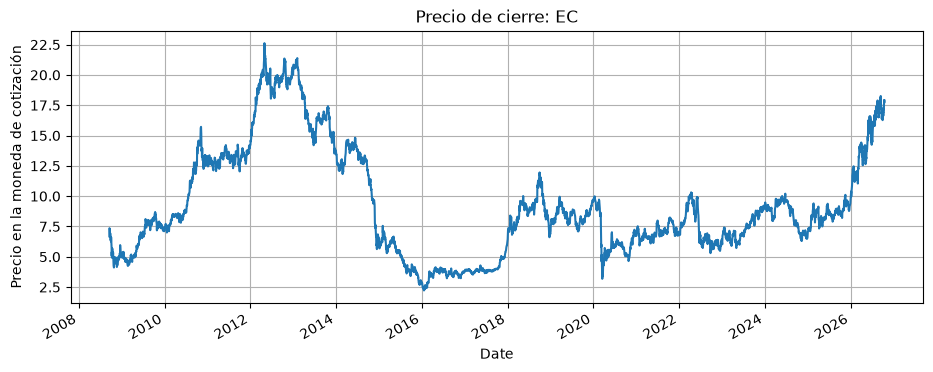

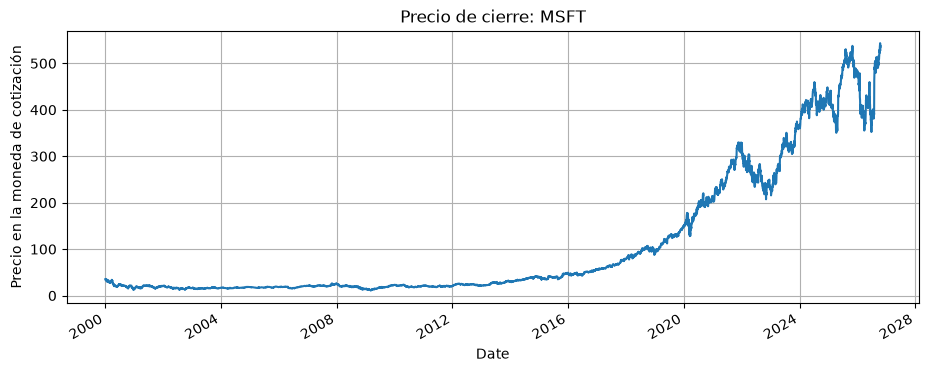

In [3]:
inicio, fin = "2000-01-01", "2026-10-18"
activos = {}
for simbolo in ["BTC-USD", "EC", "MSFT"]:
    activos[simbolo] = obtener_cierre(simbolo, inicio, fin)
    if not activos[simbolo].empty:
        activos[simbolo].plot(title=f"Precio de cierre: {simbolo}")
        plt.ylabel("Precio en la moneda de cotización")
        plt.show()

**Interpretación.** Comparar niveles de precios entre activos diferentes no equivale a comparar rentabilidades. Tampoco debe inferirse una periodicidad semanal de la presencia de días de la semana en el calendario.

### Pregunta
¿Cuántas observaciones tiene cada activo y cuál es la distancia en días entre observaciones consecutivas?

In [ ]:
for nombre, s in activos.items():
    if len(s)>1:
        saltos = s.index.to_series().diff().dt.days.value_counts().sort_index()
        print(nombre, "observaciones:",len(s))
        display(saltos.rename("frecuencia de saltos (días)").to_frame())

## 3. Casos COVID-19: de tabla ancha a serie temporal
El archivo de Johns Hopkins contiene columnas de fechas y filas por país/provincia. El cuaderno original transponía el archivo y reasignaba encabezados. Aquí hacemos la misma transformación con agrupación explícita por país, para evitar columnas duplicadas cuando existen varias provincias.

Los valores son **casos confirmados acumulados**. Para estimar los casos nuevos reportados cada día calculamos:

$$
N_t=C_t-C_{t-1}.
$$

La primera diferencia no está definida: se conserva como `NaN` hasta descartarla. Las correcciones históricas pueden producir diferencias negativas.

In [4]:
url_covid = ("https://raw.githubusercontent.com/CSSEGISandData/COVID-19/"
 "master/csse_covid_19_data/csse_covid_19_time_series/"
 "time_series_covid19_confirmed_global.csv")
covid_raw = pd.read_csv(url_covid)
columnas_fechas = covid_raw.columns[4:]
covid_paises = covid_raw.groupby("Country/Region")[columnas_fechas].sum().T
covid_paises.index = pd.to_datetime(covid_paises.index, format="%m/%d/%y")
covid_paises = covid_paises.sort_index()
display(covid_paises.iloc[:5, :5])

Country/Region,Afghanistan,Albania,Algeria,Andorra,Angola
2020-01-22,0,0,0,0,0
2020-01-23,0,0,0,0,0
2020-01-24,0,0,0,0,0
2020-01-25,0,0,0,0,0
2020-01-26,0,0,0,0,0


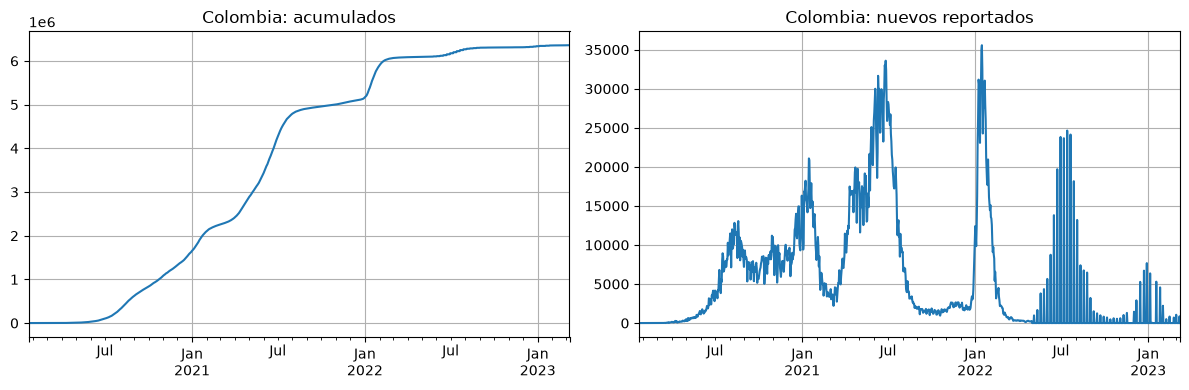

Diferencias negativas: 0


In [5]:
colombia_acum = covid_paises["Colombia"].rename("Casos acumulados")
colombia_diarios = colombia_acum.diff().dropna().rename("Casos diarios reportados")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colombia_acum.plot(ax=ax[0], title="Colombia: acumulados")
colombia_diarios.plot(ax=ax[1], title="Colombia: nuevos reportados")
plt.tight_layout()
plt.show()
print("Diferencias negativas:", (colombia_diarios<0).sum())

## 4. API pública: TRM colombiana
El cuaderno original utilizaba Socrata y el conjunto `mcec-87by`. Conservamos esa fuente, pero **no suponemos que el orden de las columnas de la respuesta sea fijo**. Primero inspeccionamos sus nombres y después convertimos fechas y valores.

In [9]:
from sodapy import Socrata
# Dataset utilizado en el cuaderno original. La disponibilidad y el esquema
# dependen del portal datos.gov.co.
with Socrata("www.datos.gov.co", None) as client:
    registros = client.get("mcec-87by", limit=10000)
trm_raw = pd.DataFrame.from_records(registros)
print("Columnas originales:", list(trm_raw.columns))
display(trm_raw.head())

Columnas originales: ['valor', 'unidad', 'vigenciadesde', 'vigenciahasta']


,valor,unidad,vigenciadesde,vigenciahasta
0,3156.32,COP,2026-10-20T00:00:00.000,2026-10-20T00:00:00.000
1,3174.67,COP,2026-10-17T00:00:00.000,2026-10-19T00:00:00.000
2,3170.46,COP,2026-10-16T00:00:00.000,2026-10-16T00:00:00.000
3,3197.65,COP,2026-10-15T00:00:00.000,2026-10-15T00:00:00.000
4,3181.74,COP,2026-10-14T00:00:00.000,2026-10-14T00:00:00.000


In [11]:
# Se conservan nombres originales: NO se renombran por posición.
candidatas_fecha = [c for c in trm_raw if "hasta" in c.lower()]
candidatas_valor = [c for c in trm_raw if ("valor" in c.lower() or "trm" in c.lower())]
print("Posibles fechas:", candidatas_fecha)
print("Posibles valores:", candidatas_valor)
#if not candidatas_fecha or not candidatas_valor:
#    raise ValueError("Revisar columnas devueltas por la API antes de continuar")
fecha_col = candidatas_fecha[0]
valor_col = candidatas_valor[0]
trm = trm_raw[[fecha_col, valor_col]].copy()
trm[fecha_col] = pd.to_datetime(trm[fecha_col], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()
trm[valor_col] = pd.to_numeric(trm[valor_col], errors="coerce")
trm = (trm.dropna().sort_values(fecha_col)
       .drop_duplicates(fecha_col, keep="last")
       .set_index(fecha_col)[valor_col].rename("TRM"))
display(trm.head())
print("Rango:", trm.index.min(), trm.index.max())

Posibles fechas: ['vigenciahasta']
Posibles valores: ['valor']


vigenciahasta
1991-12-02    643.42
1991-12-03    639.22
1991-12-04    635.70
1991-12-05    631.51
1991-12-06    627.16
Name: TRM, dtype: float64

Rango: 1991-12-02 00:00:00 2026-10-20 00:00:00


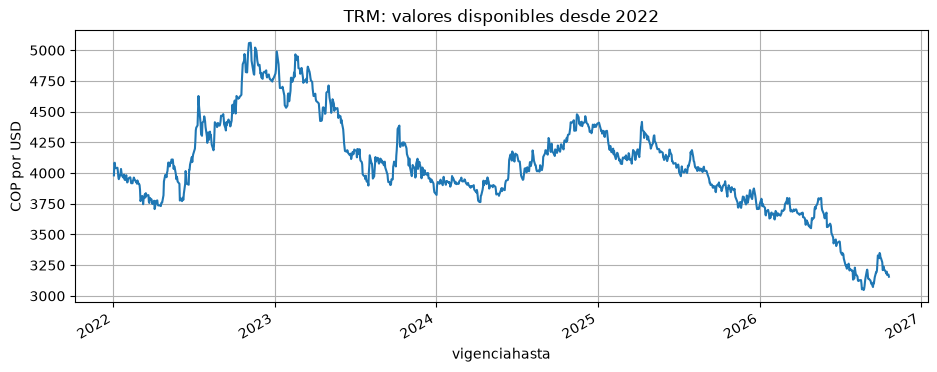

Duplicados en fecha: 0


In [12]:
trm.loc["2022-01-01":].plot(title="TRM: valores disponibles desde 2022")
plt.ylabel("COP por USD")
plt.show()
print("Duplicados en fecha:",trm.index.duplicated().sum())

## 5. Síntesis
En este cuaderno aprendimos a recuperar, convertir y visualizar datos. Antes de cualquier pronóstico es necesario verificar: unidad, calendario, valores faltantes, revisiones, duplicados y significado de las fechas.

**Actividades:** (1) comparar el número de sesiones de Microsoft y días de Bitcoin; (2) explicar por qué `diff()` genera un faltante inicial; (3) investigar si la TRM representa un precio negociado o una tasa de referencia publicada.

**Siguiente cuaderno:** concatenación, alineación de índices, frecuencia diaria e imputación.